#### Simulation settings

Paths

In [106]:
from pathlib import Path

ACC_CPP_DIR = Path("/home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp")
BINARY_FILE = ACC_CPP_DIR / "build/runner/acc_sim"
OUTPUT_ROOT = ACC_CPP_DIR / "results"


Select Scenario NCAP

In [107]:
SCENARIO_FILE = (
    ACC_CPP_DIR
    / "../../Data/OSC-NCAP-scenarios/OpenSCENARIO/NCAP"
    / "AEB_C2C_2023/NCAP_AEB_C2C_CCR_2023.xosc")


NCAP Scenario settings

In [108]:
EGO_NAME = "Ego"

# Simulation parameters
EGO_SPEED_KPH = 50.0
TARGET_SPEED_KPH = 0.0
TARGET_BRAKING_ENABLED = False


Launcher settings

In [109]:
TIMESTEP_SECONDS = 0.01
MAX_DURATION_SECONDS = 40  # Upper limit; scenario or collision may end the run earlier.
TIME_GAP_SECONDS = 1.5  # Native ACC default following time gap.
SET_SPEED_MPS = None  # None uses the scenario's initial ego speed.
STOP_ON_COLLISION = True
DETAILED_LOGS = True
VIEWER = True  # True opens live animation; build first with tools/build_native.py --viewer.
NATIVE_REFERENCE = False  # False: target copies; True: live native targets.

# esmini's ObjectSensor: one measurement per simulation timestep, no uncertainty.
IDEAL_SENSOR_ENABLED = True  # False keeps all-target copies for validation.
SENSOR_X_METRES = 0.0
SENSOR_Y_METRES = 0.0
SENSOR_Z_METRES = 0.5
SENSOR_HEADING_RADIANS = 0.0
SENSOR_NEAR_RANGE_METRES = 0.0
SENSOR_FAR_RANGE_METRES = 100.0
SENSOR_HORIZONTAL_FOV_RADIANS = 1.0471975511965976  # 60 degrees.


#### Prepare commands / launchers

In [110]:
import subprocess
import tempfile

binary = BINARY_FILE.resolve()
scenario = SCENARIO_FILE.resolve()
if not binary.is_file() or not scenario.is_file():
    raise FileNotFoundError("Check ACC_CPP_DIR, BINARY_FILE and SCENARIO_FILE in the settings cell.")
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
output_dir = Path(tempfile.mkdtemp(prefix="acc_single_", dir=OUTPUT_ROOT.resolve()))


Launcher commands & run simulation

In [111]:
# Simulation args
command = [
    str(binary), "--scenario", str(scenario), "--output-dir", str(output_dir),
    "--controller", "acc", "--dropout-p", "0",
    "--dt", str(TIMESTEP_SECONDS), "--duration", str(MAX_DURATION_SECONDS),
    "--time-gap", str(TIME_GAP_SECONDS),
    "--stop-on-collision", str(STOP_ON_COLLISION).lower(),
    "--detailed-logs", str(DETAILED_LOGS).lower(),
    "--viewer", str(VIEWER).lower(),
    "--native-reference", str(NATIVE_REFERENCE).lower(),
]

# Ideal sensor args
command += [
    "--ideal-sensor", str(IDEAL_SENSOR_ENABLED).lower(),
    "--sensor-x-m", str(SENSOR_X_METRES),
    "--sensor-y-m", str(SENSOR_Y_METRES),
    "--sensor-z-m", str(SENSOR_Z_METRES),
    "--sensor-heading-rad", str(SENSOR_HEADING_RADIANS),
    "--sensor-near-m", str(SENSOR_NEAR_RANGE_METRES),
    "--sensor-far-m", str(SENSOR_FAR_RANGE_METRES),
    "--sensor-horizontal-fov-rad", str(SENSOR_HORIZONTAL_FOV_RADIANS),
]

# NCAP scenario parameter overrides (not ACC cruise-speed settings).
command += [
    "--ego-name", EGO_NAME,
    "--ego-speed-kph", str(EGO_SPEED_KPH),
    "--target-speed-kph", str(TARGET_SPEED_KPH),
    "--target-braking", str(TARGET_BRAKING_ENABLED).lower(),
]

if SET_SPEED_MPS is not None:
    command += ["--set-speed", str(SET_SPEED_MPS)]
print("Output:", output_dir)
print(f"Using sensor option: ideal={IDEAL_SENSOR_ENABLED}")
subprocess.run(command, cwd=ACC_CPP_DIR, check=True)


Output: /home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp/results/acc_single_nsvew5r6
Using sensor option: ideal=True
esmini GIT REV: v3.8.1-0-19d26b6-dirty
esmini GIT TAG: v3.8.1
esmini GIT BRANCH: tags/v3.8.1^0
esmini BUILD VERSION: N/A - client build
[] [info] Ignoring missing default config: /home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp/build/engine-home/bin/../config.yml
Completed: "/home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp/results/acc_single_nsvew5r6"
collision=0, min_gap=3.00078 m, min_TTC=2.42359 s


CompletedProcess(args=['/home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp/build/runner/acc_sim', '--scenario', '/home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/Data/OSC-NCAP-scenarios/OpenSCENARIO/NCAP/AEB_C2C_2023/NCAP_AEB_C2C_CCR_2023.xosc', '--output-dir', '/home/danilo/Desktop/perception_uncertainty/experiments/esmini-perception/simulation/acc_cpp/results/acc_single_nsvew5r6', '--controller', 'acc', '--dropout-p', '0', '--dt', '0.01', '--duration', '40', '--time-gap', '1.5', '--stop-on-collision', 'true', '--detailed-logs', 'true', '--viewer', 'true', '--native-reference', 'false', '--ideal-sensor', 'true', '--sensor-x-m', '0.0', '--sensor-y-m', '0.0', '--sensor-z-m', '0.5', '--sensor-heading-rad', '0.0', '--sensor-near-m', '0.0', '--sensor-far-m', '100.0', '--sensor-horizontal-fov-rad', '1.0471975511965976', '--ego-name', 'Ego', '--ego-speed-kph', '50.0', '--target-speed-kph', '0.0', '--target-braking', 'false'],

#### Load generated  

In [112]:
import csv
import json

with (output_dir / "results.csv").open(newline="") as file:
    results = list(csv.DictReader(file))
with (output_dir / "detections.csv").open(newline="") as file:
    detections = list(csv.DictReader(file))
run_config = json.loads((output_dir / "run_config.json").read_text())
summary = json.loads((output_dir / "summary.json").read_text())
print(f"Loaded {len(results)} results rows")
summary


Loaded 1987 results rows


{'complete': True,
 'collision': False,
 'end_reason': 'scenario_stop',
 'duration_s': 19.860000000000305,
 'first_collision_s': None,
 'collision_ego_speed_mps': None,
 'collision_relative_speed_mps': None,
 'minimum_distance_m': 3.0007769646552873,
 'minimum_gap_m': 3.0007769646552873,
 'minimum_ttc_s': 2.423587039398215,
 'first_deceleration_s': 1.5400000000000011,
 'minimum_acceleration_mps2': -3.2067928476294583,
 'ego_final_speed_mps': 0.0004958316068410704,
 'close_gap_stop_requested': False}

#### Plots and analysis

Requires detailed logging and ipympl in the notebook kernel for interactive plots. These plots use one ego and target ID 1.

| Plot | What it tells us |
|---|---|
| Ego and target speeds | How ego responds to target motion. |
| Actual and desired gap | Whether separation approaches native ACC’s following-distance rule. |

The desired gap is recomputed from boundary speeds; it is not a logged internal ACC signal.


In [113]:
%matplotlib widget
import matplotlib.pyplot as plt

with (output_dir / "truth.csv").open() as file:
    truth = list(csv.DictReader(file))

print(f"Loaded {len(truth)} truth rows")

ego = [row for row in truth if row["role"] == "ego"]
target = [row for row in truth if row["object_id"] == "1"]

print(f"ego keys: {ego[0].keys()}")


Loaded 3974 truth rows
ego keys: dict_keys(['time_s', 'object_id', 'role', 'x_m', 'y_m', 'z_m', 'h_rad', 'speed_mps', 'length_m', 'width_m', 'height_m', 'center_x_m', 'center_y_m', 'center_z_m', 'object_type', 'object_category', 'vx_mps', 'vy_mps', 'vz_mps', 'ax_mps2', 'ay_mps2', 'az_mps2'])


/tmp/ipykernel_32496/3402547215.py:1: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(9, 8), dpi=80)


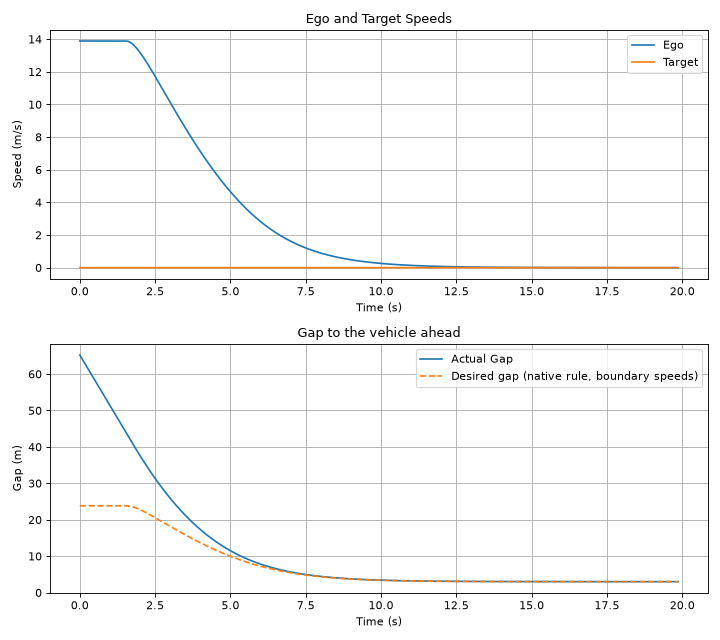

In [114]:
plt.figure(figsize=(9, 8), dpi=80)

# Speed
plt.subplot(2, 1, 1)

# Ego
plt.plot(
    [float(row["time_s"]) for row in ego],
    [float(row["speed_mps"]) for row in ego],
    label="Ego",
)

# target
plt.plot(
    [float(row["time_s"]) for row in target],
    [float(row["speed_mps"]) for row in target],
    label="Target"
)

plt.xlabel("Time (s)"); plt.ylabel("Speed (m/s)")
plt.legend(); plt.grid()
plt.title("Ego and Target Speeds")

# Actual gap
plt.subplot(2, 1, 2)

# Actual gap
plt.plot(
    [float(row["time_s"]) for row in results],
    [float(row["truth_min_gap_m"]) if row["truth_min_gap_m"] else float("nan")
    for row in results
],
    label="Actual Gap"
)

# Native ACC rule: 3 m + time gap * the larger of ego and target speed.
# Recomputed from boundary truth for this single-target run, not an internal ACC log.
desired_gap = [
    3.0 + run_config["time_gap_s"] * max(
        float(ego_row["speed_mps"]), float(target_row["speed_mps"])
    )
    for ego_row, target_row in zip(ego, target)
]

plt.plot(
    [float(row["time_s"]) for row in ego],
    desired_gap,
    "--",
    label="Desired gap (native rule, boundary speeds)",
)

plt.xlabel("Time (s)"); plt.ylabel("Gap (m)")
plt.legend(); plt.grid()
plt.title("Gap to the vehicle ahead")


plt.tight_layout()
plt.show()
